## Loading Data
* load data from the project directory

In [2]:

import numpy as np
import pandas as pd
from pathlib import Path

PROJECT_ROOT = Path(r'C:\Users\gitsw\Desktop\clear_desktop\TechnicalPortfolio\swetshgit\DL_CUDA_Excercise')
directory = PROJECT_ROOT / 'imputed_envirocar_data'
if not directory.is_dir():
    raise FileNotFoundError(f'Data directory not found: {directory}')


# Initialize an empty list to store dataframes
dfs = []

# Loop through all CSV files in the directory
for csv_file in directory.glob('*.csv'):
        # Load the CSV file into a temporary dataframe
        temp_df = pd.read_csv(csv_file)
        # Append the temporary dataframe to the list
        dfs.append(temp_df)

if not dfs:
    raise FileNotFoundError(f'No CSV files found in {directory}')

print(len(dfs), f"files successfully loaded from {directory}")

envirocar_df = pd.concat(dfs, ignore_index=True)
envirocar_df.reset_index(drop=True,inplace=True)
print(envirocar_df.shape)

856 files successfully loaded from C:\Users\gitsw\Desktop\clear_desktop\TechnicalPortfolio\swetshgit\DL_CUDA_Excercise\imputed_envirocar_data
(327527, 35)


## Imputing missing data
* remove unnecessary columns
* impute missing data

In [3]:
required_columns = [
    'id',
    'CO2(kg/h)',
    'GPS Bearing(deg)',
    'GPS Altitude(m)',
    'Speed(km/h)',
    'Rpm(u/min)',
    'GPS HDOP(precision)',
    'Throttle Position(%)',
    'Intake Temperature(c)',
    'Engine Load(%)',
    'time',
    'Consumption(l/h)',
    'MAF(l/s)',
    'GPS Speed(km/h)',
    'GPS VDOP(precision)',
    'GPS PDOP(precision)',
    'GPS Accuracy(%)'
]
df = envirocar_df.drop(columns=envirocar_df.columns.difference(required_columns))
## Show total number of cells with missing data per each column
df.isnull().sum()

id                            0
MAF(l/s)                 127931
Intake Temperature(c)     35506
Speed(km/h)                5876
Rpm(u/min)                 7639
Throttle Position(%)     105513
Engine Load(%)           103327
time                          0
GPS Altitude(m)           16952
GPS HDOP(precision)       29992
GPS Bearing(deg)          16954
GPS Speed(km/h)           16952
GPS VDOP(precision)       29992
GPS Accuracy(%)           16952
GPS PDOP(precision)       29992
CO2(kg/h)                161326
Consumption(l/h)         161326
dtype: int64

In [4]:
## imputation
df = envirocar_df.drop(columns=envirocar_df.columns.difference(required_columns))
# Define the imputation methods for each column
imputation_methods = {
    'CO2(kg/h)': 'mean',
    'GPS HDOP(precision)': 'ffill',
    'GPS Altitude(m)': 'ffill',
    'GPS Bearing(deg)': 'ffill',
    'Consumption(l/h)': 'mean',
    'Speed(km/h)': 'mean',
    'GPS Speed(km/h)': 'ffill',
    'Rpm(u/min)': 'ffill',
    'Throttle Position(%)':'mean',
    'GPS VDOP(precision)':'ffill',
    'GPS Accuracy(%)': 'ffill',
    'GPS PDOP(precision)': 'ffill',
    'Intake Temperature(c)': 'mean',
    'Engine Load(%)': 'mean',
    'MAF(l/s)': 'mean',
}

# Iterate over each column
for column in df.columns:
    if column in imputation_methods:
        imputation_method = imputation_methods[column]
        if imputation_method == 'mean':
            df[column].fillna(df[column].mean(), inplace=True)
        elif imputation_method == 'ffill':
            df[column].fillna(method='ffill', inplace=True)

#filling in remaining NaNs
df.fillna(method='bfill', inplace=True)
## Check that no missing values are present

print(df.isnull().sum())




id                       0
MAF(l/s)                 0
Intake Temperature(c)    0
Speed(km/h)              0
Rpm(u/min)               0
Throttle Position(%)     0
Engine Load(%)           0
time                     0
GPS Altitude(m)          0
GPS HDOP(precision)      0
GPS Bearing(deg)         0
GPS Speed(km/h)          0
GPS VDOP(precision)      0
GPS Accuracy(%)          0
GPS PDOP(precision)      0
CO2(kg/h)                0
Consumption(l/h)         0
dtype: int64


In [5]:
df

,id,MAF(l/s),Intake Temperature(c),Speed(km/h),Rpm(u/min),Throttle Position(%),Engine Load(%),time,GPS Altitude(m),GPS HDOP(precision),GPS Bearing(deg),GPS Speed(km/h),GPS VDOP(precision),GPS Accuracy(%),GPS PDOP(precision),CO2(kg/h),Consumption(l/h)
0,525e3e7fe4b000fe057e773f,33.360001,24.000000,36.000000,1873.000000,83.0,71.764709,2013-10-14T12:06:03Z,95.000000,0.800000,274.348323,0.000000,0.800000,4.0,1.200000,8.169363,3.395984
1,525e3e7fe4b000fe057e7741,16.020000,24.000000,32.000000,1654.000000,71.0,58.823528,2013-10-14T12:06:09Z,95.000000,0.800000,274.348323,0.000000,0.800000,4.0,1.200000,8.169363,3.395984
2,525e3e7fe4b000fe057e7743,22.469999,24.000000,34.000000,1739.000000,83.0,21.568628,2013-10-14T12:06:15Z,95.000000,0.800000,274.348323,0.000000,0.800000,4.0,1.200000,8.169363,3.395984
3,525e3e7fe4b000fe057e7745,20.379999,23.000000,14.000000,1180.000000,83.0,70.588234,2013-10-14T12:06:21Z,95.000000,0.800000,274.348323,0.000000,0.800000,4.0,1.200000,8.169363,3.395984
4,525e3e7fe4b000fe057e7747,9.380000,23.000000,4.000000,935.000000,83.0,56.470589,2013-10-14T12:06:27Z,95.000000,0.800000,274.348323,0.000000,0.800000,4.0,1.200000,8.169363,3.395984
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
327522,645f34ccca0a730aef36fbc4,33.548675,30.000000,37.000000,1179.026768,3.0,12.156863,2023-05-08T21:31:45Z,106.716183,0.800000,100.774414,35.832080,1.100000,4.0,1.300000,4.020412,1.710813
327523,645f34ccca0a730aef36fbc5,33.548675,30.000000,21.503311,976.000000,3.0,12.549020,2023-05-08T21:31:47Z,106.342843,0.875000,99.975550,24.761009,1.200000,4.0,1.500000,3.425988,1.457867
327524,645f34ccca0a730aef36fbc6,33.548675,30.000000,14.000000,1533.000000,3.0,22.745098,2023-05-08T21:31:49Z,106.194807,0.800000,64.954809,15.501523,1.159660,3.0,1.419319,7.072418,3.009540
327525,645f34ccca0a730aef36fbc7,33.548675,30.000001,18.000000,1874.000000,12.0,47.450981,2023-05-08T21:31:51Z,106.468486,0.800000,23.437498,15.587304,1.100000,3.0,1.300000,10.525083,4.478759


## Train Model
* prepare data
* create model
* train data on model
* predict on unseen data

In [10]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense
from sklearn.model_selection import train_test_split


# Select relevant features for training
features = ['GPS HDOP(precision)', 'GPS Altitude(m)', 'GPS Bearing(deg)', 'MAF(l/s)',
            'Consumption(l/h)', 'Speed(km/h)', 'GPS Speed(km/h)', 'Rpm(u/min)',
            'Throttle Position(%)', 'GPS VDOP(precision)', 'GPS PDOP(precision)',
            'GPS Accuracy(%)', 'Intake Temperature(c)', 'Engine Load(%)']
# Normalize the data
scaler = MinMaxScaler()
scaled_data = scaler.fit_transform(df[features])

# Define sequence length for LSTM
sequence_length = 10

# Create sequences for LSTM
def create_sequences(data, sequence_length):
    sequences = []
    targets = []
    for i in range(len(data) - sequence_length):
        sequences.append(data[i:i+sequence_length])
        targets.append(data[i+sequence_length][1])  # Accessing CO2(kg/h) column directly
    return np.array(sequences), np.array(targets)

X, y = create_sequences(scaled_data, sequence_length)

# Split data into training, testing, and validation
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=42)

# Build LSTM model
model = Sequential([
    LSTM(50, input_shape=(X_train.shape[1], X_train.shape[2])),
    Dense(1)
])

# Compile the model
model.compile(optimizer='adam', loss='mse')

# Train the model
training = model.fit(X_train, y_train, epochs=20, batch_size=32, validation_data=(X_val, y_val))

# Evaluate the model
loss= model.evaluate(X_test, y_test)
print("Test Loss:", loss)




Epoch 1/20
6551/6551 [==============================] - 36s 5ms/step - loss: 8.9678e-05 - val_loss: 2.5655e-05
Epoch 2/20
6551/6551 [==============================] - 33s 5ms/step - loss: 2.5956e-05 - val_loss: 2.5500e-05
Epoch 3/20
6551/6551 [==============================] - 32s 5ms/step - loss: 2.2743e-05 - val_loss: 2.2129e-05
Epoch 4/20
6551/6551 [==============================] - 35s 5ms/step - loss: 2.1495e-05 - val_loss: 2.2591e-05
Epoch 5/20
6551/6551 [==============================] - 34s 5ms/step - loss: 2.0727e-05 - val_loss: 2.2659e-05
Epoch 6/20
6551/6551 [==============================] - 33s 5ms/step - loss: 2.0294e-05 - val_loss: 2.4321e-05
Epoch 7/20
6551/6551 [==============================] - 34s 5ms/step - loss: 2.0077e-05 - val_loss: 2.2828e-05
Epoch 8/20
6551/6551 [==============================] - 34s 5ms/step - loss: 1.9912e-05 - val_loss: 2.1292e-05
Epoch 9/20
6551/6551 [==============================] - 32s 5ms/step - loss: 1.9682e-05 - val_loss: 2.1608e-05
E

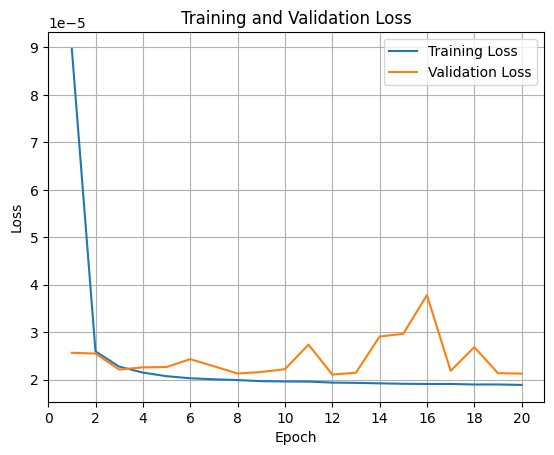

In [11]:
# Plot training loss
import matplotlib.pyplot as plt

epochs = range(1, 21)

plt.plot(epochs, training.history['loss'], label='Training Loss')
plt.plot(epochs, training.history['val_loss'], label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.xticks(range(0, 21, 2))

plt.legend()
plt.grid(True)
plt.show()

2047/2047 [==============================] - 5s 2ms/step
Mean Absolute Error (MAE): 0.0016568073206621675
Root Mean Squared Error (RMSE): 0.004344742735000874


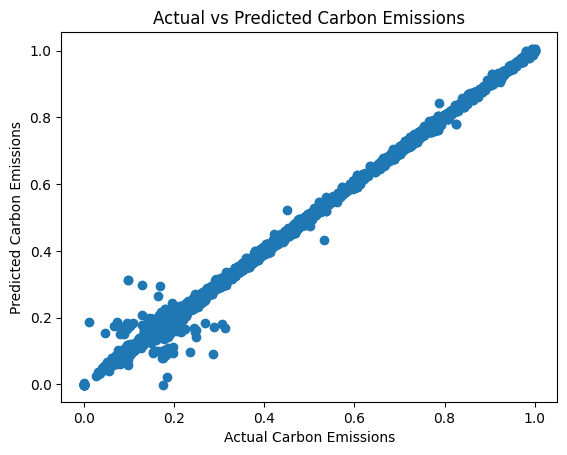

In [12]:
## Evaluating model on unseen data
from sklearn.metrics import mean_absolute_error, mean_squared_error

# # Evaluate the model
loss = model.evaluate(X_test, y_test)

# Calculate additional evaluation metrics
y_pred = model.predict(X_test)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print("Mean Absolute Error (MAE):", mae)
print("Root Mean Squared Error (RMSE):", rmse)

import matplotlib.pyplot as plt

plt.scatter(y_test, y_pred)
plt.xlabel('Actual Carbon Emissions')
plt.ylabel('Predicted Carbon Emissions')
plt.title('Actual vs Predicted Carbon Emissions')
plt.show()

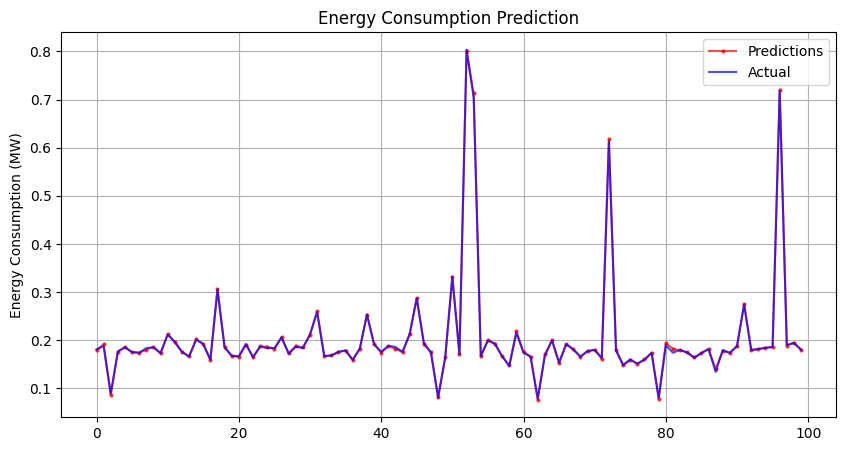

In [15]:
import matplotlib.pyplot as plt

def plot_pred(pred, true):
    pred = pred.squeeze()
    true = true.squeeze()

    plt.figure(figsize=(10, 5))  # Set a larger figure size for better visibility

    # Plot the last 100 predictions with red color, circle markers, and a bit of transparency
    plt.plot(pred[-100:], "-o", color="red", label="Predictions", markersize=2, alpha=0.7)

    # Plot the last 100 actual values with blue color and a bit of transparency
    plt.plot(true[-100:], color="blue", label="Actual", alpha=0.7)

    # Set the y-axis label
    plt.ylabel("Energy Consumption (MW)")

    # Set the title of the plot
    plt.title("Energy Consumption Prediction")

    # Display the legend to differentiate between actual and predicted values
    plt.legend()

    # Add a grid to the plot
    plt.grid(True)

    # Display the plot
    plt.show()

# Example usage (assuming y_test and y_pred are defined and are the correct shape)
plot_pred(y_pred, y_test)



## Train on more than one model
* create several models in array
* save training data to array
* plot training and val loss
* make predictions for each model
* plot predictions for each model

In [16]:
## Train more than one LSTM model.

models = [
    Sequential([
        LSTM(50, input_shape=(X_train.shape[1], X_train.shape[2])),
        Dense(1)
    ]),
    Sequential([
        LSTM(100, input_shape=(X_train.shape[1], X_train.shape[2]), return_sequences=True),
        LSTM(50),
        Dense(1)
    ]),
    Sequential([
        LSTM(64, input_shape=(X_train.shape[1], X_train.shape[2]), return_sequences=True),
        LSTM(64),
        Dense(32),
        Dense(1)
    ])
]

# Compile and train LSTM models
trainings = []
for model in models:
    model.compile(optimizer='adam', loss='mse')
    h = model.fit(X_train, y_train, epochs=20, batch_size=32, validation_data=(X_val, y_val), verbose=1)
    trainings.append(h)


Epoch 1/20
6551/6551 [==============================] - 35s 5ms/step - loss: 1.0056e-04 - val_loss: 2.7860e-05
Epoch 2/20
6551/6551 [==============================] - 34s 5ms/step - loss: 2.7317e-05 - val_loss: 2.8080e-05
Epoch 3/20
6551/6551 [==============================] - 33s 5ms/step - loss: 2.3130e-05 - val_loss: 5.6142e-05
Epoch 4/20
6551/6551 [==============================] - 31s 5ms/step - loss: 2.1480e-05 - val_loss: 2.2573e-05
Epoch 5/20
6551/6551 [==============================] - 33s 5ms/step - loss: 2.1302e-05 - val_loss: 2.2665e-05
Epoch 6/20
6551/6551 [==============================] - 33s 5ms/step - loss: 2.0932e-05 - val_loss: 3.0735e-05
Epoch 7/20
6551/6551 [==============================] - 33s 5ms/step - loss: 2.0397e-05 - val_loss: 2.1889e-05
Epoch 8/20
6551/6551 [==============================] - 33s 5ms/step - loss: 2.0240e-05 - val_loss: 2.1318e-05
Epoch 9/20
6551/6551 [==============================] - 33s 5ms/step - loss: 2.0128e-05 - val_loss: 2.1948e-05
E

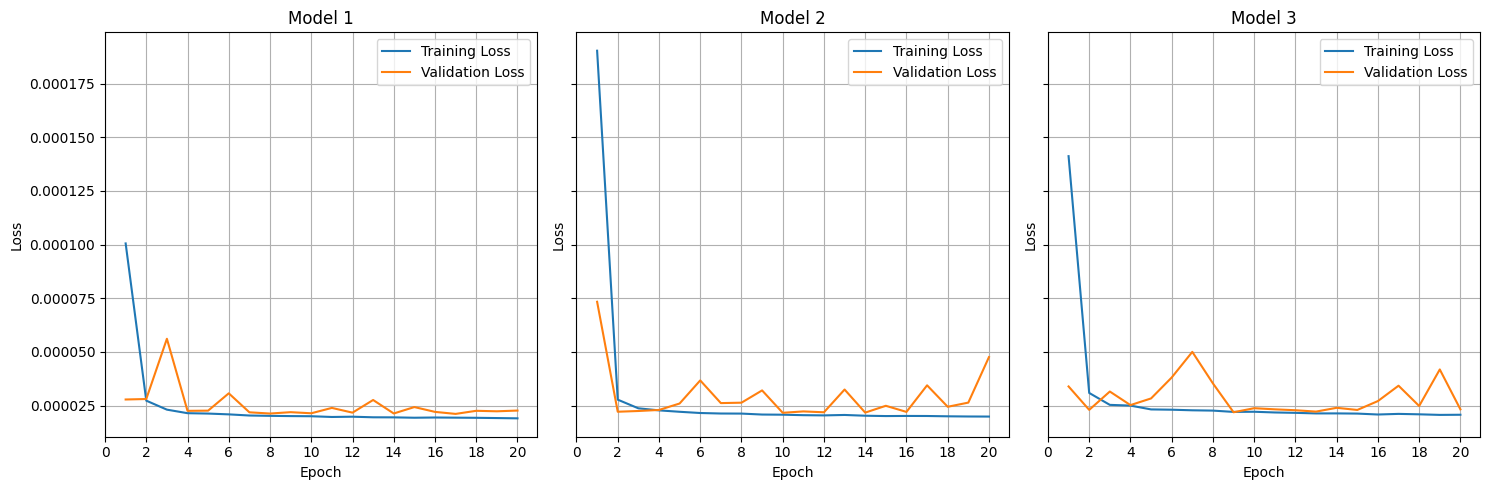

In [17]:
## plot results for models side by side

fig, axs = plt.subplots(1, 3, figsize=(15, 5),sharey=True)

for i,training_data in enumerate(trainings):
    axs[i].plot(epochs, training_data.history['loss'], label='Training Loss')
    axs[i].plot(epochs, training_data.history['val_loss'], label='Validation Loss')
    axs[i].set_title('Model {}'.format(i+1))
    axs[i].set_xlabel('Epoch')
    axs[i].set_ylabel('Loss')
    axs[i].legend()
    axs[i].grid(True)
    axs[i].set_xticks(range(0, 21, 2))

plt.tight_layout()
plt.show()

In [18]:
## make predictions for each model

predictions = []
for model in models:
  y_pred_model = model.predict(X_test)
  predictions.append(y_pred_model)


2047/2047 [==============================] - 6s 2ms/step


In [19]:
predictions

[array([[0.19988886],
        [0.46387735],
        [0.17724505],
        ...,
        [0.19015476],
        [0.19614118],
        [0.1816084 ]], dtype=float32),
 array([[0.20329061],
        [0.46991158],
        [0.18079753],
        ...,
        [0.19337651],
        [0.19917294],
        [0.18513644]], dtype=float32),
 array([[0.19838357],
        [0.4582827 ],
        [0.17673317],
        ...,
        [0.18902531],
        [0.19520606],
        [0.18032521]], dtype=float32)]

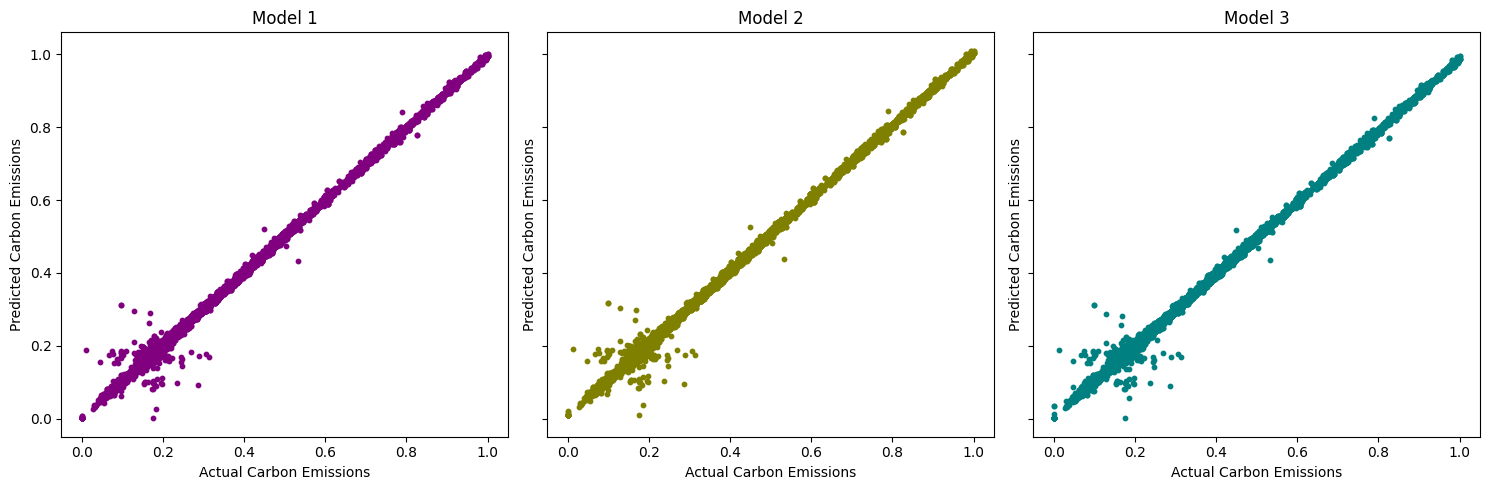

In [20]:
##plotting predictions for each model side by side


colors = ['purple', 'olive', 'teal']

fig, axs = plt.subplots(1, 3, figsize=(15, 5),sharey=True)
for i, y_pred in enumerate(predictions):
    axs[i].scatter(y_test, y_pred, s=10, color=colors[i])
    axs[i].set_title('Model {}'.format(i+1))
    axs[i].set_xlabel("Actual Carbon Emissions")
    axs[i].set_ylabel('Predicted Carbon Emissions')

plt.tight_layout()
plt.show()

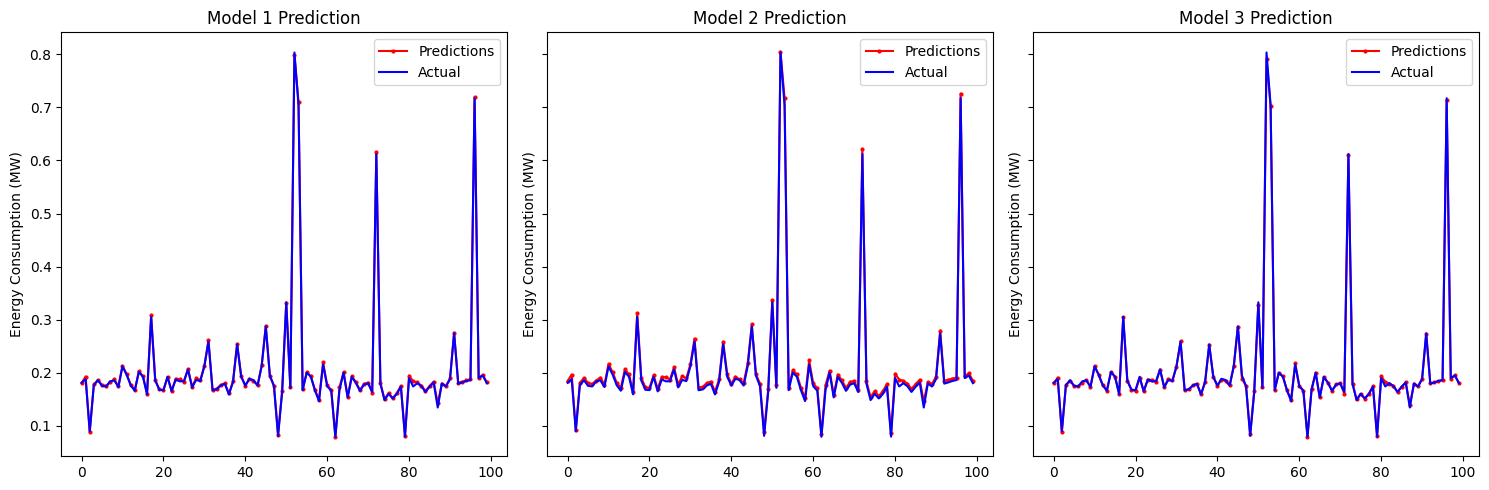

In [21]:
import matplotlib.pyplot as plt

def plot_pred(pred, true, ax, model_num):
    pred = pred.squeeze()[-100:]  # Squeeze to 1D and take last 100 points
    true = true.squeeze()[-100:]  # Squeeze to 1D and take last 100 points

    ax.plot(pred, "-o", color="r", label="Predictions", markersize=2)
    ax.plot(true, color="b", label="Actual")
    ax.set_ylabel("Energy Consumption (MW)")
    ax.set_title(f"Model {model_num} Prediction")
    ax.legend()

fig, axs = plt.subplots(1, 3, figsize=(15, 5), sharey=True)  # Create 3 subplots

# Loop through each model's predictions and plot them on a separate subplot
for i, y_pred in enumerate(predictions):
    plot_pred(y_pred, y_test, axs[i], i+1)

plt.tight_layout()
plt.show()


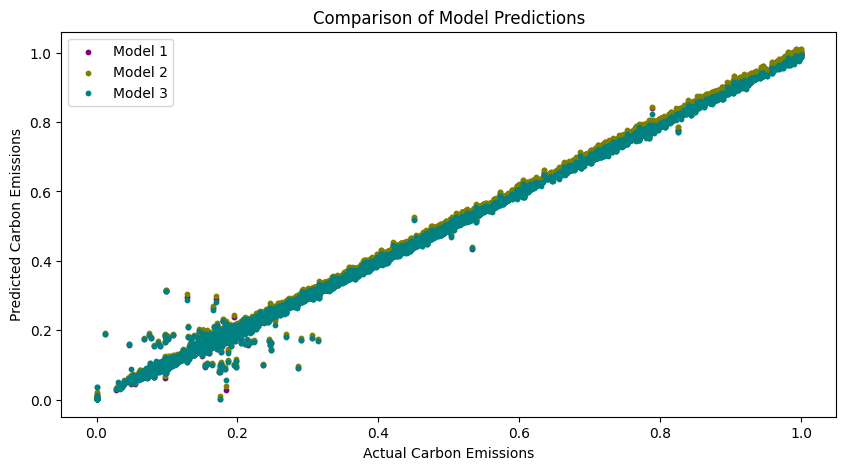

In [22]:
## all in one chart

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 5))

for i, y_pred in enumerate(predictions):
    ax.scatter(y_test, y_pred, s=10, label='Model {}'.format(i+1), color=colors[i])

ax.set_xlabel("Actual Carbon Emissions")
ax.set_ylabel('Predicted Carbon Emissions')
ax.set_title('Comparison of Model Predictions')
ax.legend()

plt.show()